In [ ]:
# Basic set of Python Data Analysis
import numpy as np
import pandas as pd
pd.set_option('display.max_rows',None)
pd.set_option('display.width',180)
pd.set_option('display.max_colwidth', 20)
from tqdm.auto import tqdm
tqdm.pandas(desc="Progress")

## for plot by matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import itertools
from cycler import cycler
import seaborn as sns

# for plot by matplotlib
sns.set(font="Serif", font_scale=2.0,
        rc={'figure.figsize': (10, 10),
            'lines.markersize': 15,
            "animation.embed_limit": 100})
sns.mpl.rc("axes", prop_cycle
           =cycler('color', ['#E24A33', '#348ABD', '#988ED5',
                             '#777777', '#FBC15E', '#8EBA42',
                             '#FFB5B8']))
sns.set_style('darkgrid', {'axes.facecolor': "0.8"})

# for markers
marker = itertools.cycle(('o', 'v', '^', 'D', '+', 'X', '<', '>'))
colors = itertools.cycle(('#E24A33', '#348ABD', '#988ED5', '#777777',
                          '#FBC15E', '#8EBA42', '#FFB5B8'))

# speedup scikit-learn by intelex
from sklearnex import patch_sklearn
patch_sklearn()

## don't show warning
import warnings
warnings.filterwarnings('ignore')

# import the Escal Tools
import os
import sys
sys.path.append(os.path.expanduser("../../scripts/EscalTK"))

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [2]:
%reload_ext autoreload
%autoreload 2
import basicTools as bt

# Basic Data and Setup

## Setup

In [9]:
## set the data prefix
gmxdir = "/home/ghzuo/data/gromacs/"
# filePref=f"{gmxdir}data.Villin/1yrf/1us/325"
# filePref=f"{gmxdir}data.Villin/1yrf/1us/350"
# filePref = f"{gmxdir}data.Villin/1yrf/50us/cut5us/u350u50-dih"
# filePref=f"{gmxdir}data.Villin/1yrf/htSeed/unfolding.375.step50/clust-gromos_0.6/350/clst000_2"
# filePref=f"{gmxdir}data.Villin/1yrf/htSeed/unfolding.375.step50/clust-gromos_0.6/350/clst001_0"
# filePref=f"{gmxdir}data.Villin/1yrf/htSeed/unfolding.375.step50/clust-gromos_0.6/350/clst002_0"
# filePref=f"{gmxdir}data.Villin/1yrf/htSeed/unfolding.375.step50/clust-gromos_0.6/350/clst003_0"
# filePref=f"{gmxdir}data.Villin/1yrf/htSeed/unfolding.375.step50/clust-gromos_0.6/350/clst005_1"
# filePref=f"{gmxdir}data.Chignolin/5awl/folding/u375u50"
# filePref=f"{gmxdir}data.Chignolin/5awl/1us/u375k1u"
# filePref=f"{gmxdir}data.ProteinL/2ptl/unfolding/375"
# filePref=f"{gmxdir}data.ProteinG/3gb1/unfolding/415"
# filePref=f"{gmxdir}data.TrpCage/2jof/unfolding/350"
# filePrefdir}data.Wdir}data.WW/2f21/unfolding/400"
filePref=f"../../data/new/Chignolin_375-dih-MLP3L32F"

## set the feature type
feature = "dih"  #dih or dist

In [10]:
### similar metrix
similar = bt.dist.cosin

### smooth
step    = 100
width   = step * 2
seg2vec = bt.segment.mean

### evalute method
evalute = bt.evalute.cluster

## read network result

In [11]:
import pickle

# read data from file
data = pickle.load(open(f"{filePref}.pkl", 'rb'))
# setup data variables
rescl = data["rescl"]
efft = data["efft"]
sal = data["saliency"]
qmc = data["qmc"]
rms = data["rms"]
netname = data['net']
args = data['args']

## Score of Kappa

Text(27.8, 0.8461496990114219, '24 (11.5 MHz)\nQMC = 0.89')

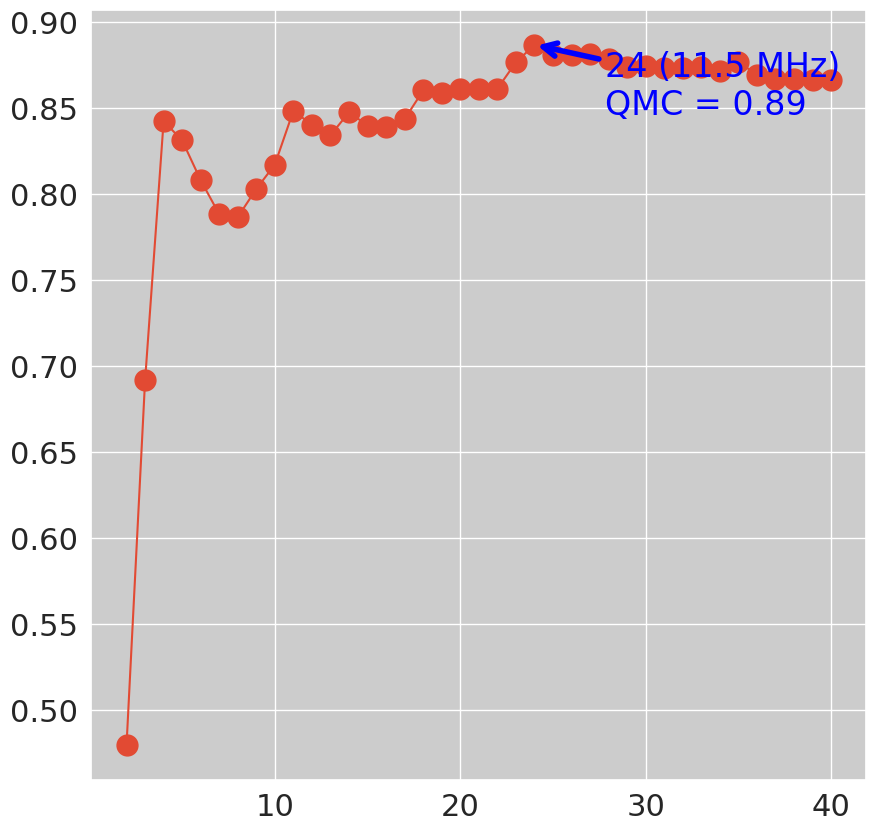

In [12]:
## plot the multiple correlation coefficient
plt.plot(qmc['list'][:,0],qmc['list'][:,1], marker="o")

## annotate the peak value
xy     = (qmc['KappaMax'], qmc['qmcMax'])
offset = 0.1 * (np.max(qmc['list'], axis=0)-np.min(qmc['list'],axis=0))
xytxt  = [xy[0] + offset[0], xy[1] - offset[1]]
plt.annotate(f"{int(xy[0]):2d} ({(xy[0]-1)*efft.ufreq:.1f} MHz)\nQMC = {xy[1]:.2f}",
            xy=xy, xytext=xytxt, color='blue', 
            arrowprops=dict(arrowstyle="->", color='blue', lw=4))

## RMSD from Native Structure

Text(0.5, 0, 'RMSD (nm)')

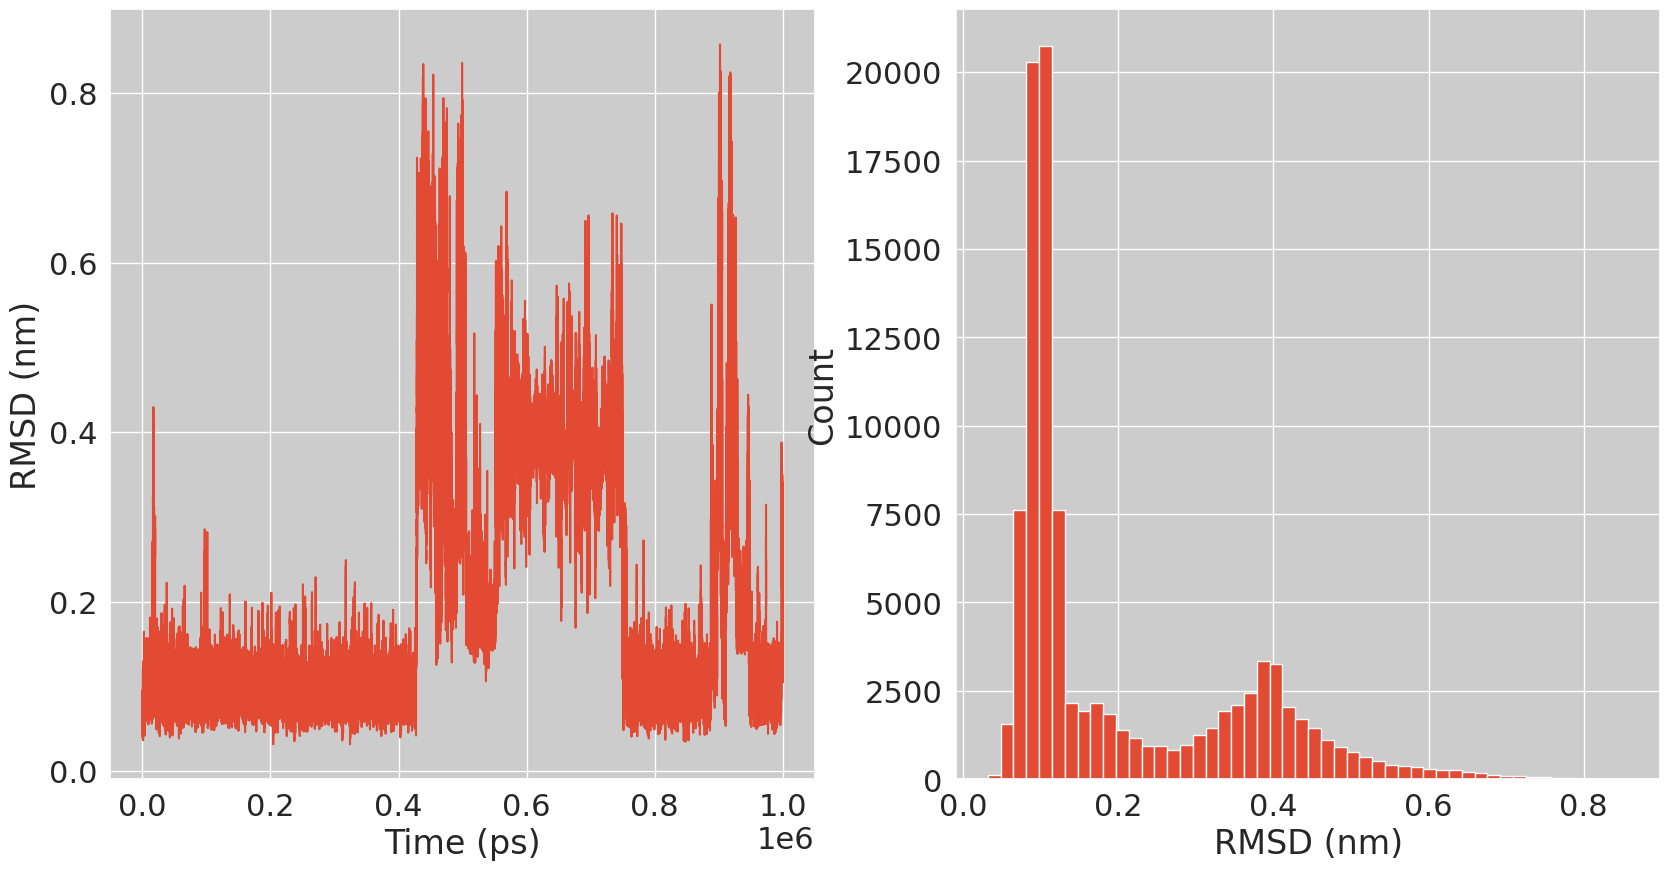

In [13]:
plt.figure(12,figsize=(20,10))
ax = plt.subplot(121)
ax.plot(rms['time'], rms['rms'])
plt.xlabel("Time (ps)")
plt.ylabel("RMSD (nm)")
ax = plt.subplot(122)
hist = ax.hist(rms["rms"], bins=50)
plt.ylabel("Count")
plt.xlabel("RMSD (nm)")

# Scaling of Selected Kappa

## Weight of Features

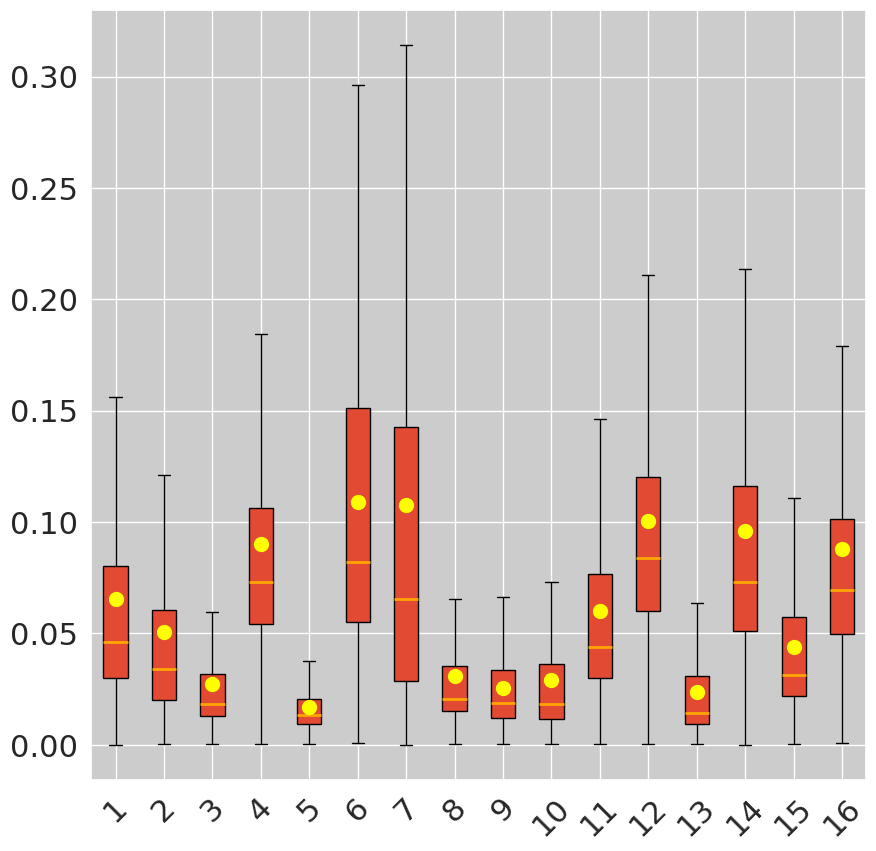

In [14]:
if sal is None:
    bt.plot.coefplot(bt.feature.dihCombind(rescl['A']) if feature == "dih" else rescl['A'])
else:
    if feature == 'dih':
        sal = bt.feature.dihCombind(sal)
    bt.plot.saliplot(sal.T)

## Effective Energy

In [15]:
args.kappa

np.float64(24.0)

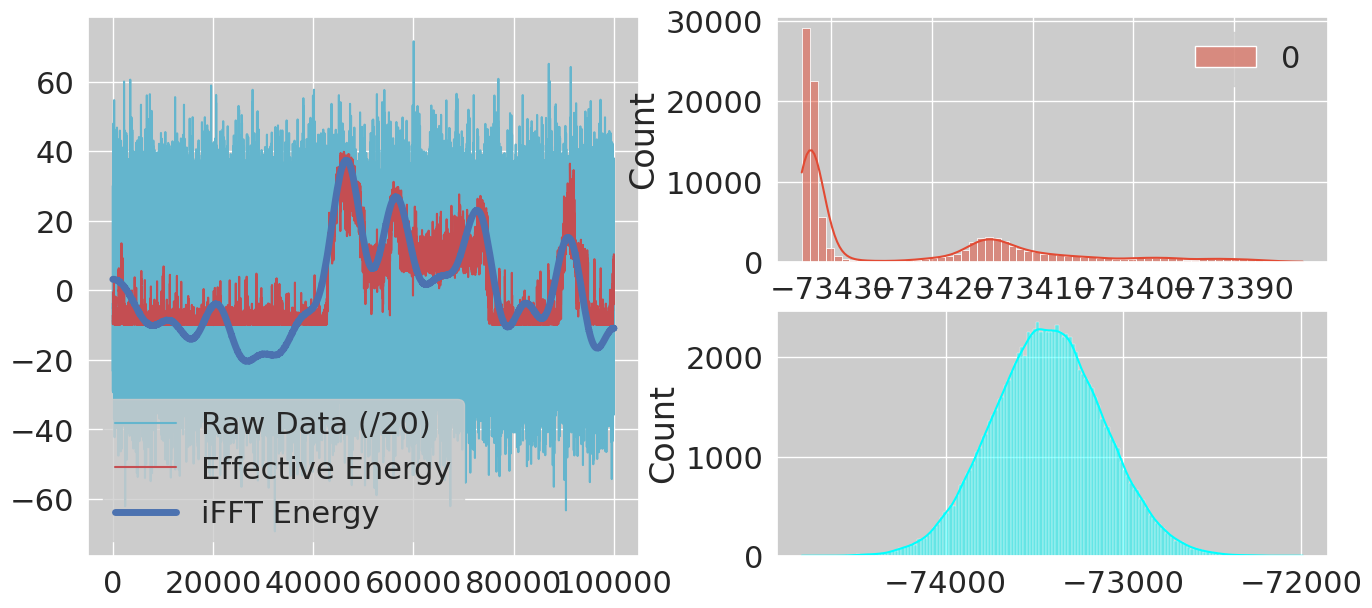

In [16]:
## plot the effective energy
bt.plot.efplot(efft.E0, efft.Ef(args.kappa), rescl['Ee'])

## Distribution & Free Energy

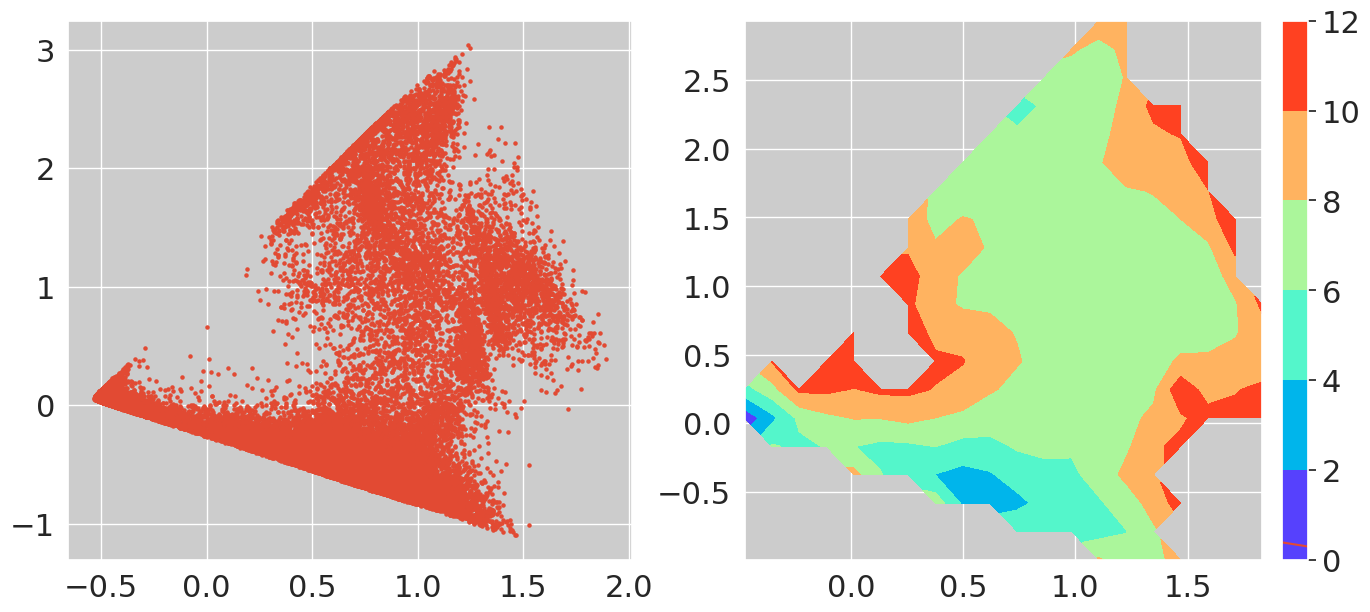

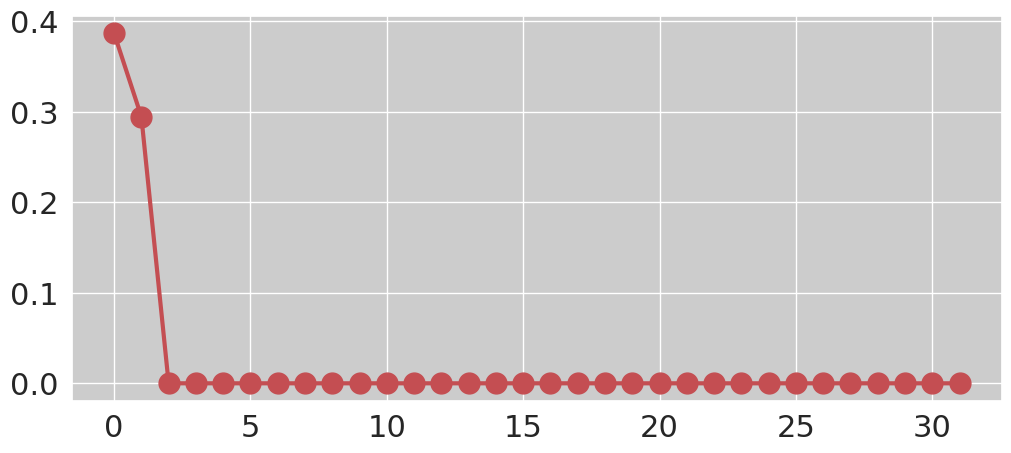

In [17]:
from sklearn.decomposition import PCA

if rescl['X'].shape[1] == 2:
    bt.plot.distr_plot(rescl['X'])
else:
    ## plot by PCA eigen vector
    pca = PCA()
    bt.plot.distr_plot(pca.fit_transform(rescl['X'])[:, :2])
    plt.plot(pca.explained_variance_)
    plt.figure(figsize=(12,5))
    plt.plot(pca.explained_variance_, "ro-", ms=15, lw=3)

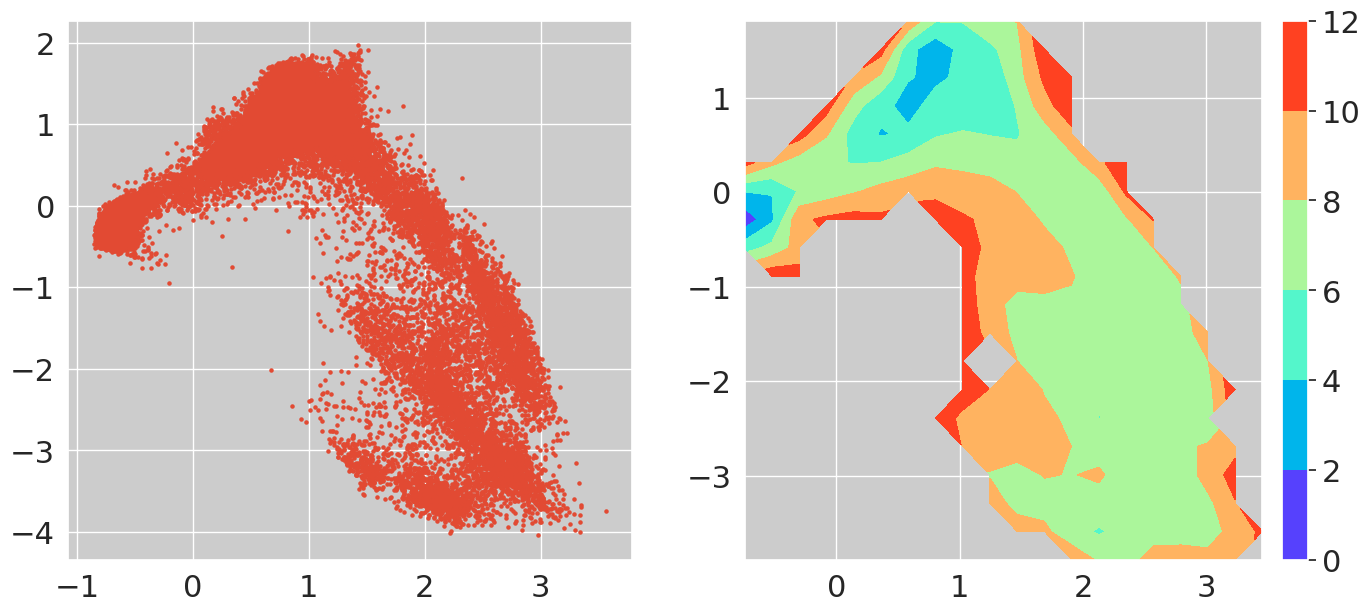

In [18]:
## plot by TICA eigen vector
from deeptime.decomposition import TICA

tica = TICA(lagtime=20, dim=2, epsilon=1e-10)
m_tica = tica.fit_fetch(rescl['X']) 
bt.plot.distr_plot(m_tica.transform(rescl['X']))

# Matrix Analysis

## Sample Data

In [19]:
## get the samples
X0s = seg2vec(efft.Xx, step, width)
Xys = seg2vec(rescl['X'], step, width)

## Testing Similarity Matrix

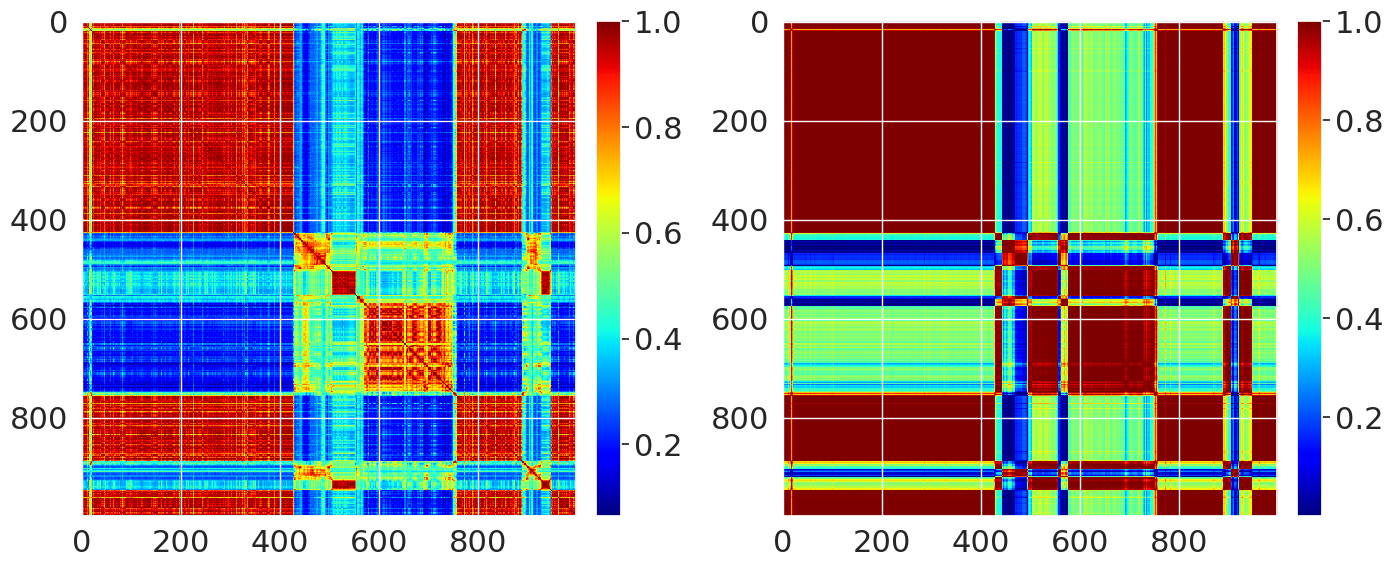

In [20]:
## set distance function and get distance
Smat0  = similar(X0s)
Smaty  = similar(Xys)

### plot
fig, axs = plt.subplots(1,2, figsize=(16,32)) 
fig.subplots_adjust(wspace=0.3)
bt.plot.implot(Smat0, axs[0])
bt.plot.implot(Smaty, axs[1])

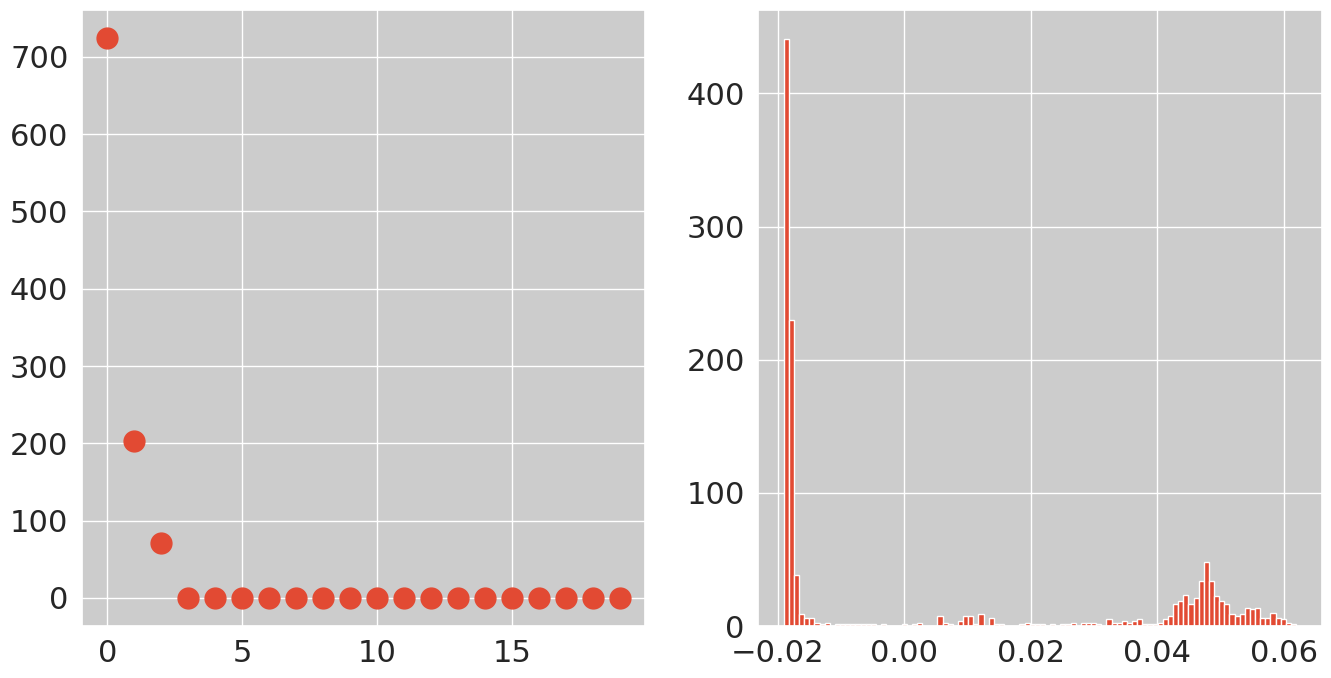

In [21]:
w,v = np.linalg.eig(Smaty)

fig, axs = plt.subplots(1,2, figsize=(16,8)) 
axs[0].plot(w[0:20], "o")
hist = axs[1].hist(v[:,1], bins=100, density=True)

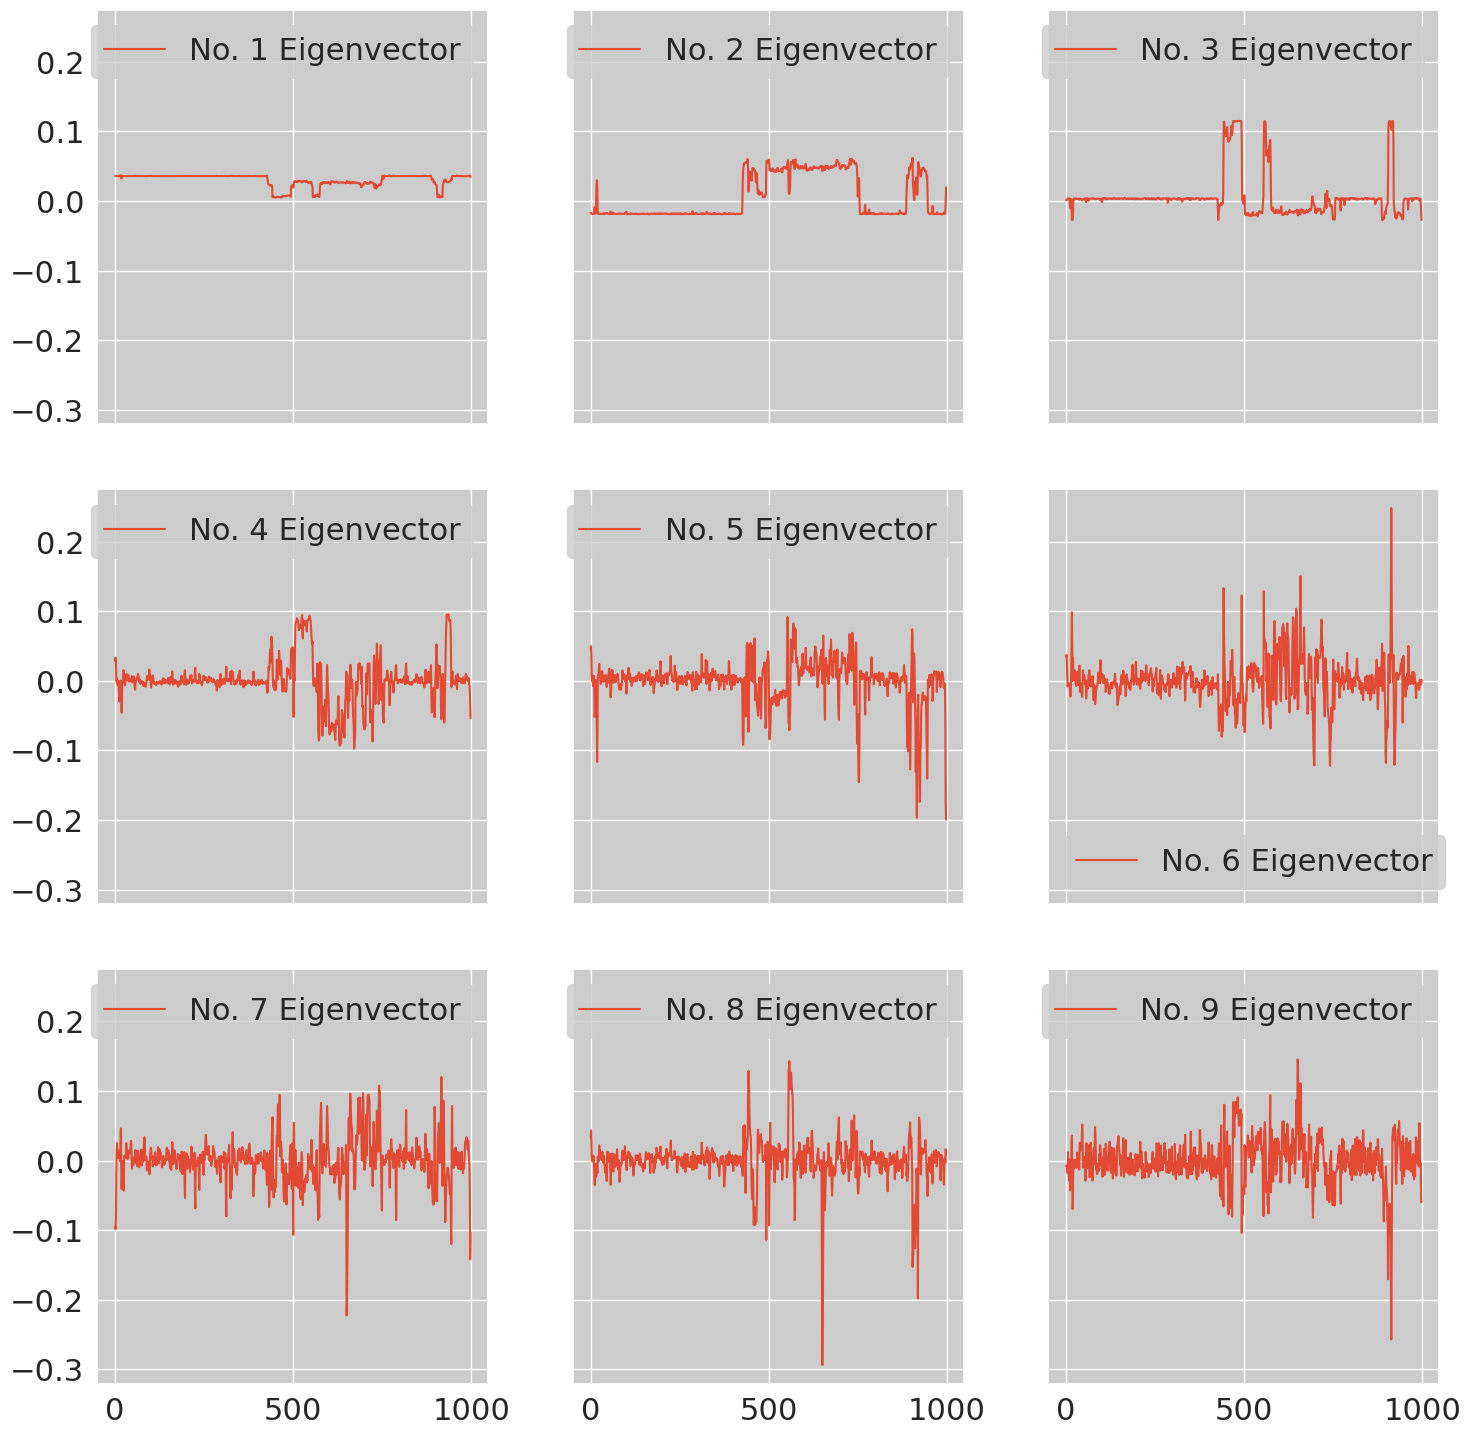

In [22]:
fig, axs = plt.subplots(3,3,sharex=True,sharey=True, figsize=(15,15)) 
sel = range(0,np.size(axs))
fig.tight_layout()
for ax, key in zip(axs.reshape(len(sel)), sel): 
    ax.plot(v[:,key])
    ax.legend(labels =["No. " + str(key+1) + " Eigenvector"])

# Clustering

In [23]:
outcl = {}

## Kmeans

In [24]:
from sklearn.cluster import KMeans

In [25]:
## Test KMean parameters
def testKMn(n):
    cl = KMeans(n_clusters=n,n_init=50).fit_predict(Xys)
    return evalute(Xys, cl)

score_KMean = pd.DataFrame({'ncluster':np.arange(2,10)})
score_KMean['score'] = score_KMean['ncluster'].progress_apply(testKMn)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

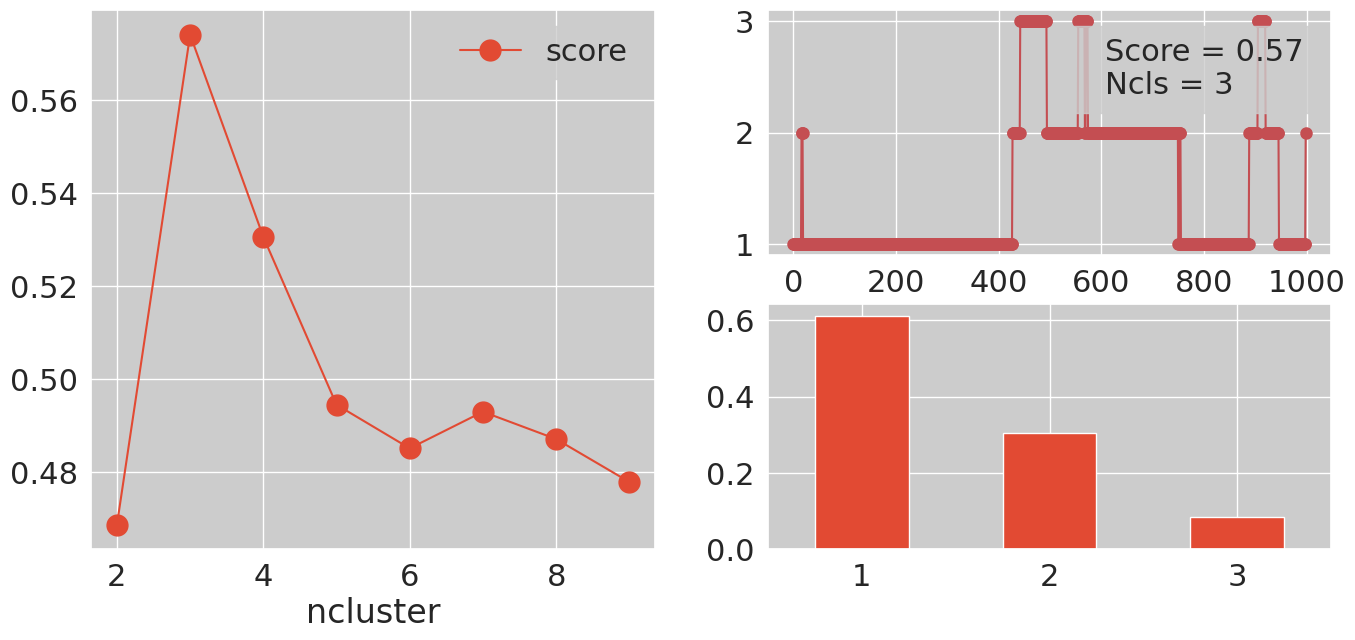

In [26]:
idxPeak = score_KMean['score'].idxmax()
ncls = score_KMean.loc[idxPeak,'ncluster']
cl = KMeans(n_clusters=ncls,n_init=50).fit_predict(Xys)
score = evalute(Xys, cl)

## get the best cluster
outcl['Kmeans'] = {'score':score, 'cl':cl, 'ncluster':ncls}

## plot data
lab = f"Score = {score:.2f}\nNcls = {ncls}"
bt.plot.clplot(score_KMean.set_index('ncluster'), cl, lab)

## Kmeans on Cosine Similarity

In [27]:
## Test KMean parameters
from sklearn.preprocessing import normalize
XysN = normalize(Xys, norm='l2')

def testKMeansNorm(n):
    cl = KMeans(n_clusters=n,n_init=50).fit_predict(XysN)
    return evalute(Xys, cl)

score_KMean_Cosin = pd.DataFrame({'ncluster':np.arange(2,10)})
score_KMean_Cosin['score'] = score_KMean['ncluster'].progress_apply(testKMeansNorm)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

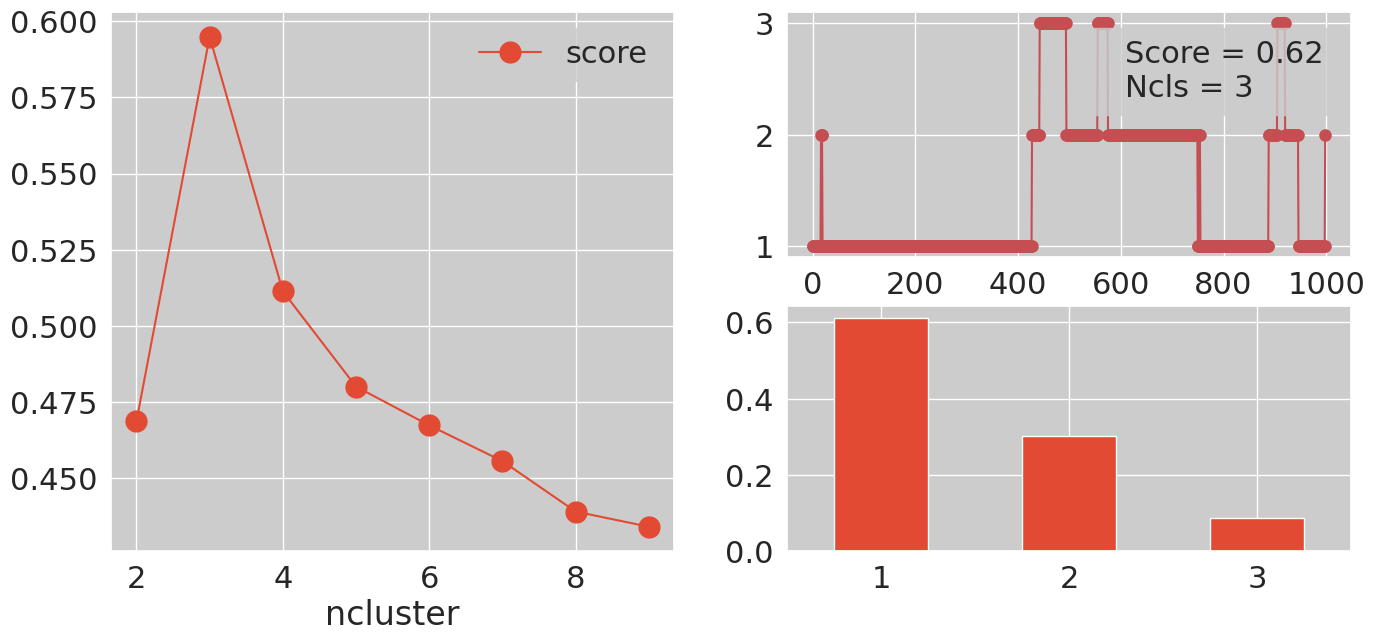

In [28]:
idxPeak = score_KMean_Cosin['score'].idxmax()
ncls = score_KMean_Cosin.loc[idxPeak,'ncluster']
cl = KMeans(n_clusters=ncls,n_init=50).fit_predict(XysN)
score = evalute(XysN, cl)

## get the best cluster
outcl['Kmeans_Cosin'] = {'score':score, 'cl':cl, 'ncluster':ncls}

## plot data
lab = f"Score = {score:.2f}\nNcls = {ncls}"
bt.plot.clplot(score_KMean_Cosin.set_index('ncluster'), cl, lab)

## KMediods on Trajectory

In [29]:
from kmedoids import KMedoids

In [30]:
## Testing Kmediods parameters by trajectory
def testKMs(n):
    cl = KMedoids(n_clusters=n, method="fasterpam", metric="euclidean").fit_predict(Xys)
    return evalute(Xys, cl)

score_KMedoids = pd.DataFrame({'ncluster':np.arange(2,10)})
score_KMedoids['score'] = score_KMedoids['ncluster'].progress_apply(testKMs)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

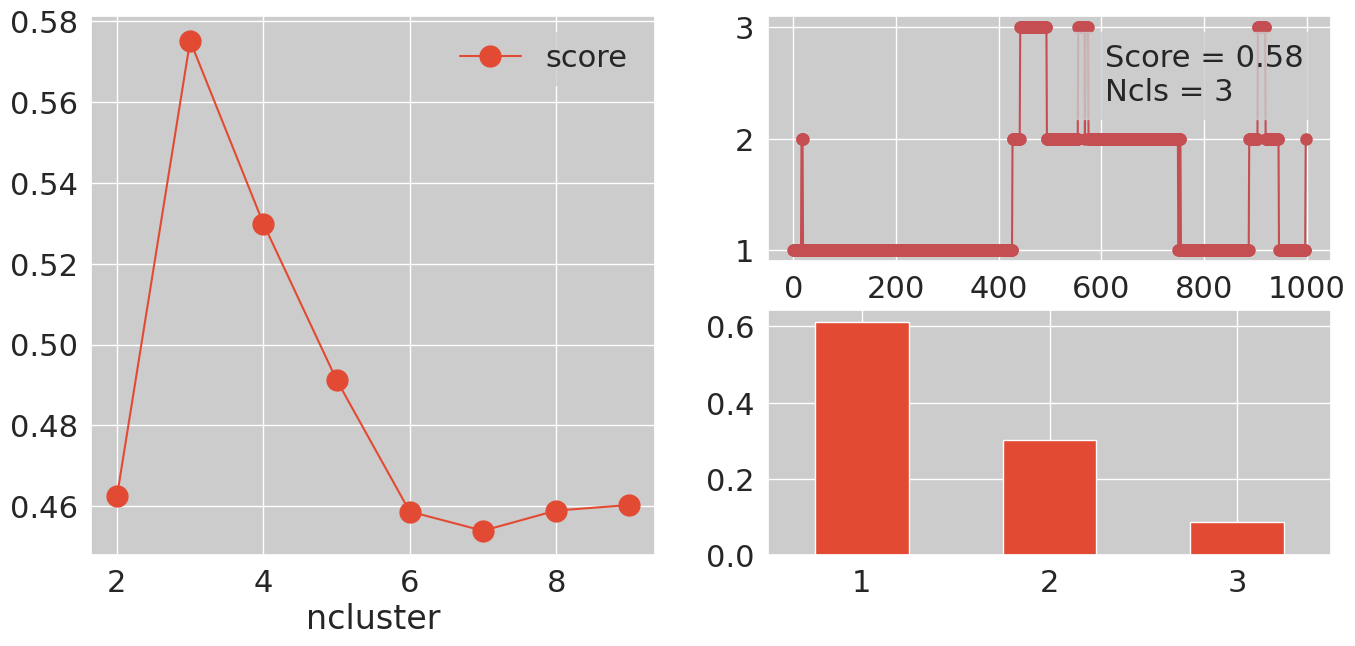

In [31]:
idxPeak = score_KMedoids['score'].idxmax()
ncls = score_KMedoids.loc[idxPeak,'ncluster']
cl = KMedoids(n_clusters=int(ncls), method="fasterpam", metric="euclidean").fit_predict(Xys)
score = evalute(Xys, cl)

## get the best cluster
outcl['KMedTraj'] = {'score':score, 'cl':cl, 'ncluster':ncls}

### plot data
lab = f"Score = {score:.2f}\nNcls = {ncls}"
bt.plot.clplot(score_KMedoids.set_index('ncluster'), cl, lab)

## KMediods on Matrix

In [32]:
## Testing Kmedoids by matrix
Dmat = 1.001 - Smaty
#Dmat = Smaty
def testKMsm(n):
    cl = KMedoids(n_clusters=n, metric='precomputed').fit_predict(Dmat)
    return evalute(Xys, cl)

### get the score
score_KMedoidsMat = pd.DataFrame({'ncluster':np.arange(2,10)})
score_KMedoidsMat['score'] = score_KMedoidsMat['ncluster'].progress_apply(testKMsm)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

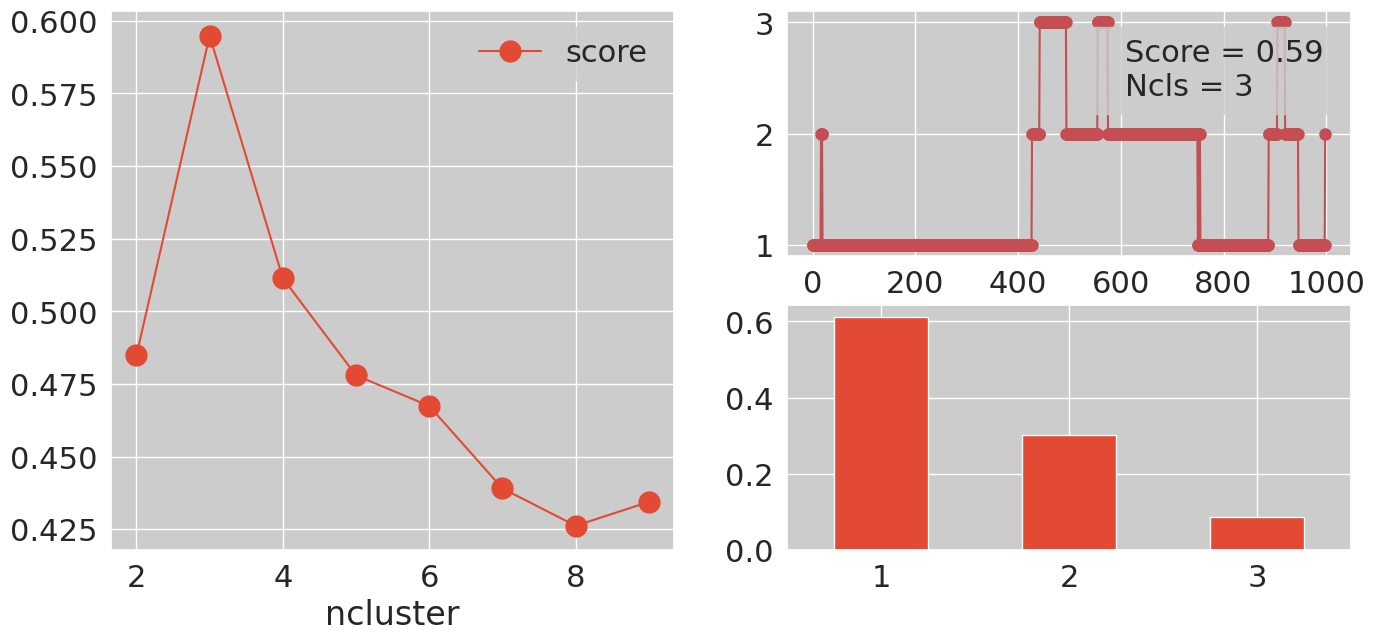

In [33]:
### find the top score parameter
idxPeak = score_KMedoidsMat['score'].idxmax()
ncls = score_KMedoidsMat.loc[idxPeak,'ncluster']
cl = KMedoids(n_clusters=int(ncls), metric='precomputed').fit_predict(Dmat)
score = evalute(Xys, cl)
lab = f"Score = {score:.2f}\nNcls = {ncls}"

## get the best cluster
outcl['KMedMatrix'] = {'score':score, 'cl':cl, 'ncluster':ncls}

### plot data
bt.plot.clplot(score_KMedoidsMat.set_index('ncluster'), cl, lab)

## GMM

In [34]:
from sklearn.mixture import GaussianMixture

In [35]:
# Test KMean parameters
def testGMM(n):
    cl = GaussianMixture(n_components=n,n_init=50).fit_predict(Xys)
    return evalute(Xys, cl)

score_GMM = pd.DataFrame({'ncluster':np.arange(2,10)})
score_GMM['score'] = score_GMM['ncluster'].progress_apply(testGMM)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

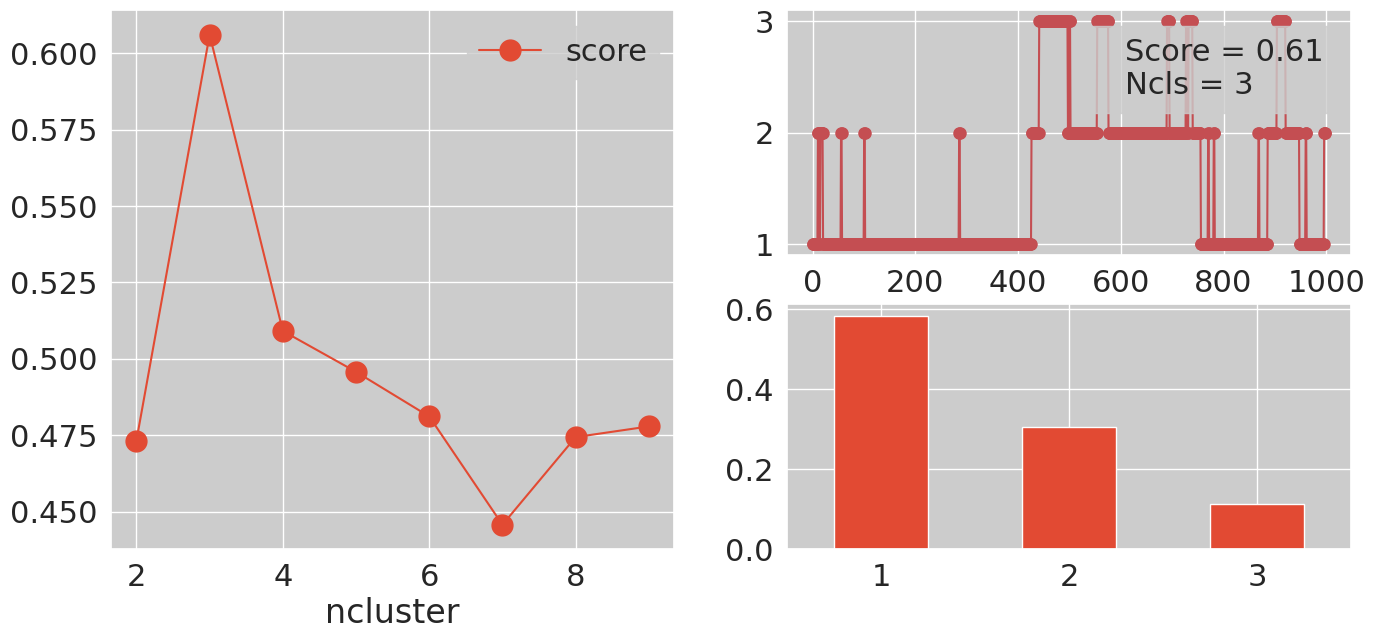

In [36]:
### find the top score parameter
idxPeak = score_GMM['score'].idxmax()
ncls = score_GMM.loc[idxPeak,'ncluster']
cl = GaussianMixture(n_components=ncls, n_init=50).fit_predict(Xys)
score = evalute(Xys, cl)

## get the best cluster
outcl['GMM'] = {'score':score, 'cl':cl, 'ncluster':ncls}

### plot data
lab = f"Score = {score:.2f}\nNcls = {ncls}"
bt.plot.clplot(score_GMM.set_index('ncluster'), cl, lab)

## Spectral Clustering on Trajectory

In [37]:
from sklearn.cluster import SpectralClustering

In [38]:
def testSCt(raw):
    cl = SpectralClustering(n_clusters=int(raw['ncls']), gamma=raw['gamma']).fit_predict(Xys)
    return evalute(Xys, cl)

# get score 
score_Spectral=pd.DataFrame(list(itertools.product([0.05, 0.1, 0.5, 1], np.arange(2,10))), 
                             columns=["gamma", "ncls"])
score_Spectral['score'] = score_Spectral.progress_apply(testSCt, axis=1)

Progress:   0%|          | 0/32 [00:00<?, ?it/s]

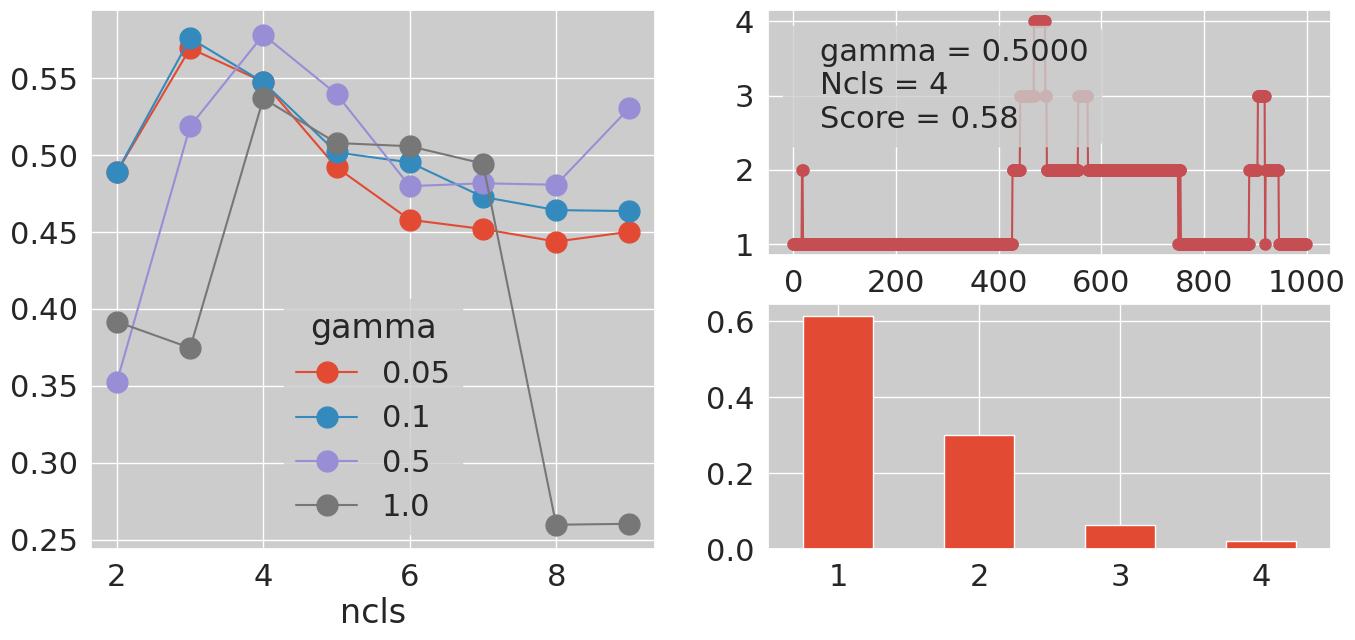

In [39]:
idxPeak = score_Spectral['score'].idxmax()
gamma   = score_Spectral.loc[idxPeak,"gamma"]
ncls    = score_Spectral.loc[idxPeak, "ncls"].astype(int)
cl  = SpectralClustering(n_clusters=ncls, gamma=gamma).fit_predict(Xys)
score = evalute(Xys, cl)

## get the best cluster
outcl['SpecTraj'] = {'score':score, 'cl':cl, 'ncluster':ncls}

### plot data
lab = f"gamma = {gamma:.4f}\nNcls = {ncls}\nScore = {score:.2f}"
bt.plot.clplot(score_Spectral.pivot(index='ncls', columns="gamma", values="score"), cl, lab)

## Spectral Clustering on Matrix

In [40]:
## Testing Spectral Clustering by matrix
def testSCm(n):
    cl = SpectralClustering(n_clusters=n, affinity='precomputed').fit_predict(Smaty)
    return evalute(Xys, cl)

### get the score
score_SpectralMat = pd.DataFrame({'ncluster':np.arange(2,10)})
score_SpectralMat['score'] = score_SpectralMat['ncluster'].progress_apply(testSCm)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

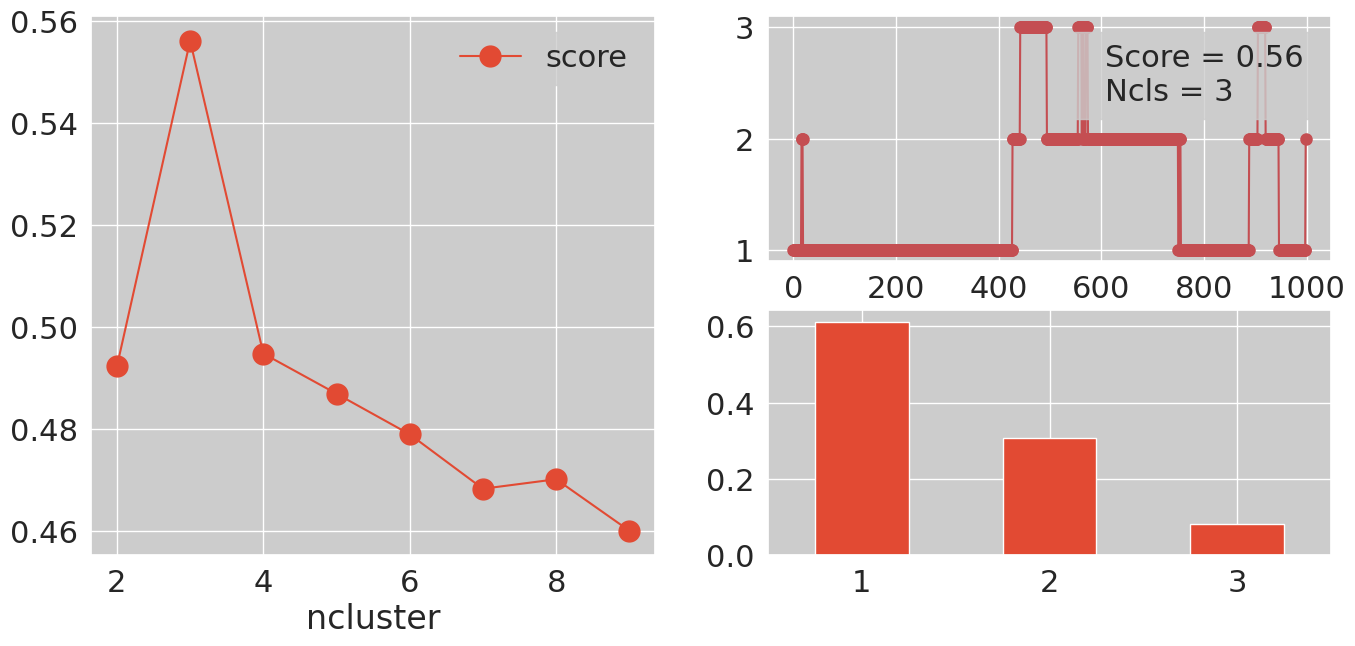

In [41]:
### find the top score parameter
idxPeak = score_SpectralMat['score'].idxmax()
ncls = score_SpectralMat.loc[idxPeak,'ncluster']
cl = SpectralClustering(n_clusters=ncls, affinity='precomputed').fit_predict(Smaty)
score = evalute(Xys, cl)

## get the best cluster
outcl['SpecMatrix'] = {'score':score, 'cl':cl, 'ncluster':ncls}

### plot data
lab = f"Score = {score:.2f}\nNcls = {ncls}"
bt.plot.clplot(score_SpectralMat.set_index('ncluster'), cl, lab)

## DBSCAN

In [42]:
from sklearn.cluster import DBSCAN

In [43]:
def testDBSCAN(raw):
    cl = DBSCAN(eps=raw['cutoff'], min_samples=int(raw['Min Samples'])).fit_predict(Xys)
    return evalute(Xys, cl) 
    
## Testing DBSCAN parameters
score_DBSCAN = pd.DataFrame(list(itertools.product([0.06, 0.08, 0.10, 0.12, 0.14], np.arange(5,20,2))), 
                            columns=["cutoff", "Min Samples"])
score_DBSCAN['score'] = score_DBSCAN.progress_apply(testDBSCAN, axis=1)

Progress:   0%|          | 0/40 [00:00<?, ?it/s]

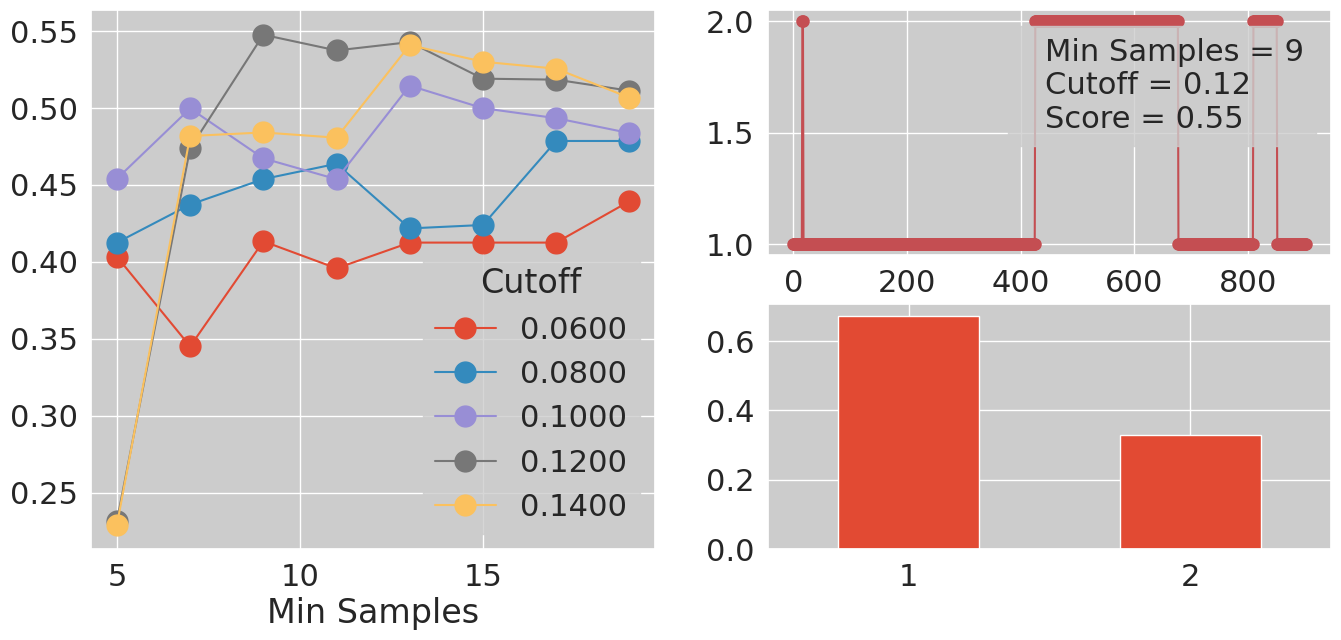

In [44]:
### the opt parameter
idxPeak = score_DBSCAN['score'].idxmax()
f  = score_DBSCAN.loc[idxPeak,"cutoff"]
n  = score_DBSCAN.loc[idxPeak, "Min Samples"].astype(int)
cl = DBSCAN(eps=f, min_samples=n).fit_predict(Xys)
score = evalute(Xys, cl)

## get the best cluster
cl = cl[cl != -1]
ncls = len(np.unique(cl))
outcl['DBSCAN'] = {'score':score, 'cl':cl, 'ncluster':ncls}

#### plot data
lab = f"Min Samples = {n}\nCutoff = {f:.2f}\nScore = {score:.2f}"
score_DBSCAN['Cutoff'] = score_DBSCAN['cutoff'].map(lambda x:f"{x:.4f}")
bt.plot.clplot(score_DBSCAN.pivot(index='Min Samples', columns="Cutoff", values="score"), cl, lab)

## PCCA+

In [45]:
from deeptime.markov import pcca

In [46]:
## get Transition matrix
Tmat = np.asarray(bt.dist.expm(Xys, 5.0), dtype=np.float64)
Tmat /= Tmat.sum (axis= 1 , keepdims=True)

# check the transition matrix for second value about one
w = np.linalg.eigvalsh(Tmat)
print(np.sort(w)[::-1][:10])

[1.02674466 1.00059349 0.98458703 0.90945235 0.72360356 0.66006739
 0.48727107 0.43159547 0.4247223  0.3997183 ]


In [47]:
### Testing PCCA paraters
def testPCCA(n):
    cl = pcca(Tmat, n)
    return evalute(Xys, cl.assignments)

### get the score
score_PCCA = pd.DataFrame({'ncluster':np.arange(2,10)})
score_PCCA['score'] = score_PCCA['ncluster'].progress_apply(testPCCA)

Progress:   0%|          | 0/8 [00:00<?, ?it/s]

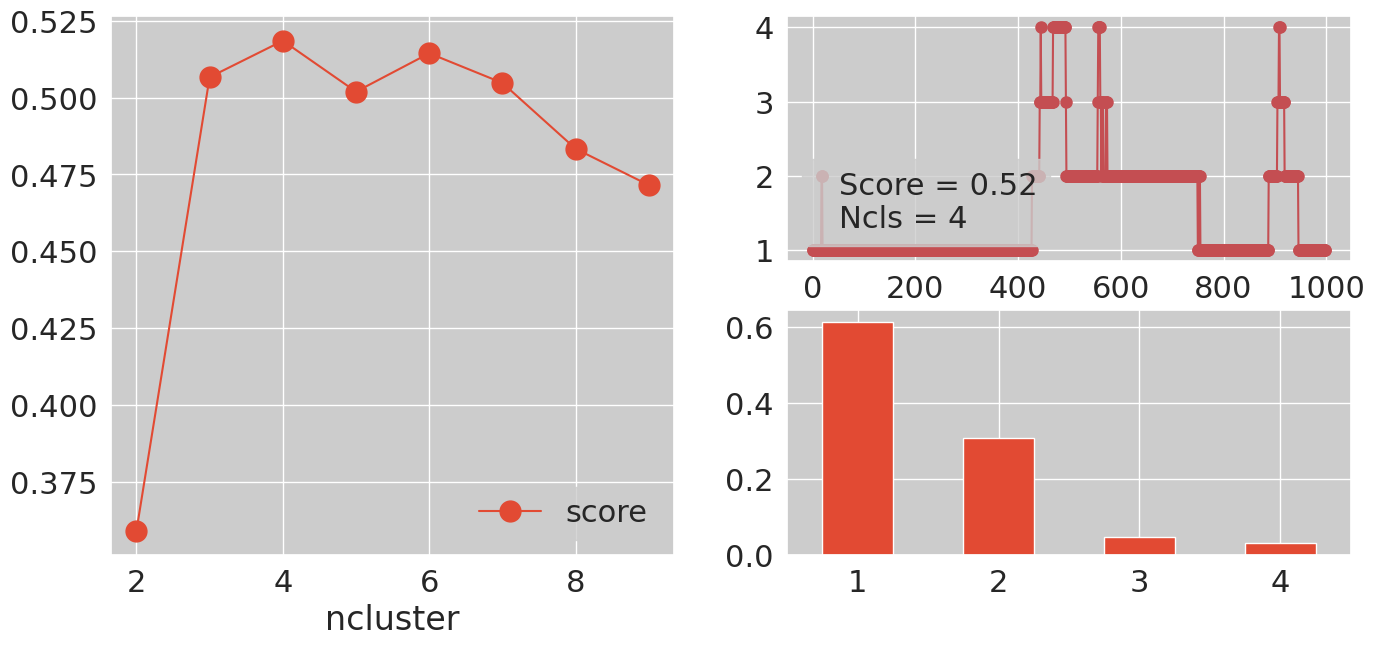

In [48]:
### find the top score parameter
idxPeak = score_PCCA ['score'].idxmax()
ncls = score_PCCA.loc[idxPeak,'ncluster']
cl = pcca(Tmat, ncls)
score = evalute(Xys, cl.assignments)

## get the best cluster
outcl['PCCA+'] = {'score':score, 'cl':cl.assignments, 'ncluster':cl.n_metastable}

### plot data
lab = f"Score = {score:.2f}\nNcls = {cl.n_metastable}"
bt.plot.clplot(score_PCCA.set_index("ncluster"), cl.assignments, lab)

## Clustering results

In [49]:
pd.DataFrame(outcl).loc[['score', 'ncluster'],:]\
    .T.sort_values(ascending=False, by='score')

,score,ncluster
Kmeans_Cosin,0.6246,3
GMM,0.606092,3
KMedMatrix,0.594862,3
SpecTraj,0.578111,4
KMedTraj,0.57515,3
Kmeans,0.574056,3
SpecMatrix,0.556136,3
DBSCAN,0.547536,2
PCCA+,0.518542,4


# Save Data

In [50]:
## save current ipynb
try:
    from ipylab import JupyterFrontEnd
    app = JupyterFrontEnd()
    app.commands.execute('docmanager:save')
except Exception as e:
    print(f"Auto-save skipped ({e.__class__.__name__}); press Ctrl+S to save.")

Auto-save skipped (ModuleNotFoundError); press Ctrl+S to save.


In [51]:
## record output to pdf
#nbname = os.path.basename(app.sessions.get_state().get('current_session').get('path'))
nbname = 'EscalNet-soloTraj.ipynb'
srcpath = %pwd
srcfile = f"{srcpath}/{nbname}"
fname = os.path.basename(filePref)
datadir = os.path.dirname(filePref)
outfile = f"EscalNet-{netname}-{fname}.pdf"

!jupyter nbconvert --to pdf --no-input --log-level 40 \
    --output-dir {datadir} --output {outfile} {srcfile}